# Session 8 lecture: Correlation and regression

<p class="lead">
Two numbers that move together are tempting: more advertising, more revenue; bigger discounts, lower profit. This lecture shows how to see a relationship, measure its strength, draw the best straight line through it and say what that line does and does not mean for a business decision.
</p>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aayush181509/AnalyticsLecture/blob/main/notebooks/08_correlation_and_regression_lecture.ipynb)

Open this notebook in Google Colab with the button above, then run each cell from top to bottom with **Shift + Enter**. Save your own copy with **File → Save a copy in Drive**.

---

## Recap quiz

Before we start, answer the quiz at the end of the [Session 7 lecture](07_trends_and_growth_lecture.md). Write short answers; we discuss them together.

---

## What you will be able to explain

1. How to read a **scatter plot**: direction, strength, shape and unusual points.
2. What **covariance** and **correlation** measure, and why correlation has no units.
3. The difference between **Pearson** and **Spearman** correlation, and when to prefer Spearman.
4. Why **correlation is not causation**: confounders, reverse causation and coincidence.
5. How a **simple linear regression** draws the best straight line, and how to say its **slope** and **intercept** in business language.
6. What **R²** and **residuals** tell you, and how to read a **residual plot**.
7. How one **outlier** or **high-leverage point** can move the line, and why **extrapolation** is dangerous.
8. Why a regression slope from past data is an **association**, not the effect of spending more.

This lecture builds on the section on correlation and causation in [How statistics can mislead](../foundations/misleading-statistics.md). In the **Lab** you apply every idea to retail discounts and to synthetic advertising data.

> **How to use the questions in this notebook**
>
> **Predict, then reveal** boxes ask you to guess before running the next cell. Write your guess down first. **Check your understanding** boxes are short questions to answer in your own words.

Run the two setup cells first. The first downloads the course's **synthetic** marketing data, used in the worked case at the end. The second sets up the charts. For the demonstrations we **simulate** small datasets with numpy; a fixed **seed** makes the "random" numbers the same every time, so your output matches everyone else's.

In [1]:
# Marketing data setup (synthetic). Run this cell first.
# Downloads the course's synthetic marketing data from GitHub and checks it is the exact version this course uses.
import hashlib
import io
import os
import urllib.request

import pandas as pd

MARKETING_URL = "https://raw.githubusercontent.com/Aayush181509/AnalyticsLecture/main/data/synthetic/marketing-v1/"
MARKETING_SHA256 = {
    "marketing_daily.csv": "1cbfc8e1c91ae72d18364b2d13bdf6db513c4aec28c339ef8b91f87a60dc0a07",
    "ab_test.csv": "41a3662997111b66d7ab1eb899f4b32e26bd64c66284ce881db6b8a7300ad47f",
}
MARKETING_DIR = os.environ.get("COURSE_MARKETING_DIR", "")


def load_marketing(name):
    """Load one marketing-v1 file: 'marketing_daily.csv' or 'ab_test.csv'."""
    if MARKETING_DIR:
        with open(os.path.join(MARKETING_DIR, name), "rb") as f:
            data = f.read()
    else:
        data = urllib.request.urlopen(MARKETING_URL + name).read()
    if hashlib.sha256(data).hexdigest() != MARKETING_SHA256[name]:
        print("WARNING: this file differs from the course version. Ask your facilitator.")
    return pd.read_csv(io.BytesIO(data), parse_dates=["date"])


print("Marketing setup complete.")

Marketing setup complete.


In [2]:
import matplotlib.pyplot as plt
import numpy as np

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a"]),
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})
print("Plot style ready.")

Plot style ready.


---

## Part 1: Scatter plots

A **scatter plot** puts one measure on each axis and draws one dot per row. It is the first thing to draw whenever you ask "do these two numbers move together?".

Read a scatter plot in four steps:

| Step | Question | Words to use |
|---|---|---|
| 1. **Direction** | When x is higher, is y usually higher or lower? | positive, negative, none |
| 2. **Strength** | How tightly do the dots follow one path? | strong, moderate, weak |
| 3. **Shape** | Is the path a straight line or a curve? | linear, curved |
| 4. **Unusual points** | Are any dots far from the rest? | outlier |

The cell below simulates four pairs of measures with different relationships.

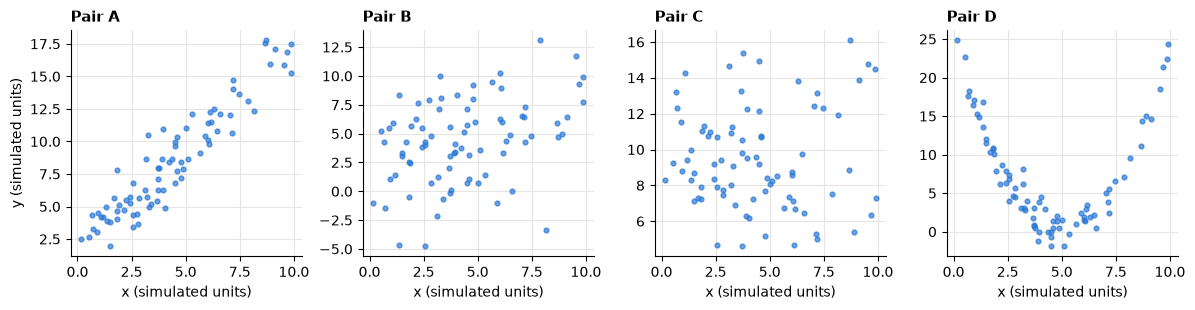

In [3]:
rng = np.random.default_rng(seed=8)
n = 80
x = rng.uniform(0, 10, n)
examples = {
    "A": 2 + 1.5 * x + rng.normal(0, 1.5, n),
    "B": 2 + 0.5 * x + rng.normal(0, 3, n),
    "C": rng.normal(10, 3, n),
    "D": (x - 5) ** 2 + rng.normal(0, 1.5, n),
}

fig, axes = plt.subplots(1, 4, figsize=(12, 3.2), sharex=True)
for ax, (label, y) in zip(axes, examples.items()):
    ax.scatter(x, y, s=12, alpha=0.7)
    ax.set_title(f"Pair {label}", fontsize=11)
    ax.set_xlabel("x (simulated units)")
axes[0].set_ylabel("y (simulated units)")
fig.tight_layout()
plt.show()

> **Predict, then reveal**
>
> Describe each pair with the four steps. Then rank them from the strongest to the weakest **straight-line** relationship. Which pair has a clear relationship that is **not** a straight line? Keep your answers; the next part puts a number on each.

---

## Part 2: Covariance and correlation

We use a small simulated café for the next parts: 60 summer days, the day's highest **temperature** and the number of **iced drinks** sold.

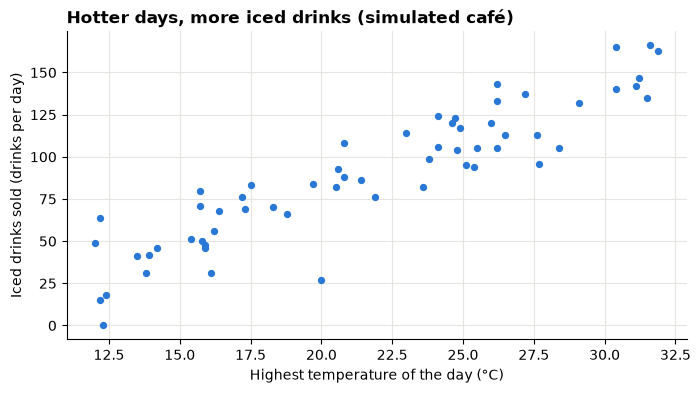

,temp_c,iced_drinks
count,60.00,60.00
mean,21.62,89.22
std,5.99,39.84
min,12.00,0.00
max,31.90,166.00


In [4]:
rng = np.random.default_rng(seed=21)
temp = rng.uniform(12, 32, 60).round(1)
drinks = (-40 + 6 * temp + rng.normal(0, 18, 60)).round().clip(min=0) + 0
cafe = pd.DataFrame({"temp_c": temp, "iced_drinks": drinks})

ax = cafe.plot.scatter(x="temp_c", y="iced_drinks", s=18)
ax.set_title("Hotter days, more iced drinks (simulated café)")
ax.set_xlabel("Highest temperature of the day (°C)")
ax.set_ylabel("Iced drinks sold (drinks per day)")
plt.show()
cafe.describe().loc[["count", "mean", "std", "min", "max"]]

### Covariance: do the two move together?

Draw a cross through the **mean** temperature and the **mean** number of drinks. Every day then sits in one of four corners.

- Hot **and** busy (top right) or cool **and** quiet (bottom left): the two deviations from the mean have the **same sign**, so their product is **positive**.
- Hot but quiet, or cool but busy: the product is **negative**.

**Covariance** is (almost) the average of those products: *sum of (x − mean x) × (y − mean y), divided by n − 1*. Mostly positive products give a positive covariance.

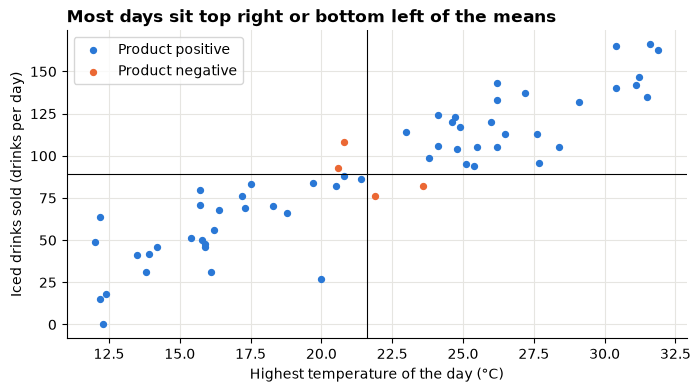

Days with a positive product: 56 of 60
Covariance by hand:   217.92
Covariance by pandas: 217.92


In [5]:
dx = cafe["temp_c"] - cafe["temp_c"].mean()
dy = cafe["iced_drinks"] - cafe["iced_drinks"].mean()
same_sign = (dx * dy) > 0

fig, ax = plt.subplots()
ax.scatter(cafe["temp_c"][same_sign], cafe["iced_drinks"][same_sign], s=18, label="Product positive")
ax.scatter(cafe["temp_c"][~same_sign], cafe["iced_drinks"][~same_sign], s=18, label="Product negative")
ax.axvline(cafe["temp_c"].mean(), color="black", linewidth=0.8)
ax.axhline(cafe["iced_drinks"].mean(), color="black", linewidth=0.8)
ax.set_title("Most days sit top right or bottom left of the means")
ax.set_xlabel("Highest temperature of the day (°C)")
ax.set_ylabel("Iced drinks sold (drinks per day)")
ax.legend()
plt.show()

cov_by_hand = (dx * dy).sum() / (len(cafe) - 1)
print("Days with a positive product:", same_sign.sum(), "of", len(cafe))
print("Covariance by hand:  ", round(cov_by_hand, 2))
print("Covariance by pandas:", round(cafe["temp_c"].cov(cafe["iced_drinks"]), 2))

### Correlation: covariance without units

Covariance is measured in "°C × drinks", which nobody can picture, and it changes if you change the units. **Pearson's correlation** *r* divides the covariance by both standard deviations:

*r = covariance ÷ (standard deviation of x × standard deviation of y)*

The units cancel, so *r* is always between **−1** and **+1**.

> **Predict, then reveal**
>
> We measure the same days in degrees **Fahrenheit** instead of Celsius. Will the covariance change? Will the correlation change?

In [6]:
temp_f = cafe["temp_c"] * 9 / 5 + 32

r_by_hand = cafe["temp_c"].cov(cafe["iced_drinks"]) / (cafe["temp_c"].std() * cafe["iced_drinks"].std())
pd.DataFrame({
    "covariance": [cafe["temp_c"].cov(cafe["iced_drinks"]), temp_f.cov(cafe["iced_drinks"])],
    "correlation r": [cafe["temp_c"].corr(cafe["iced_drinks"]), temp_f.corr(cafe["iced_drinks"])],
}, index=["temperature in °C", "temperature in °F"]).round(3)

,covariance,correlation r
temperature in °C,217.92,0.91
temperature in °F,392.26,0.91


In [7]:
print("Pearson r by hand:", round(r_by_hand, 3))
print("Pearson r for the four pairs in Part 1:")
for label, y in examples.items():
    print(f"  Pair {label}: r = {np.corrcoef(x, y)[0, 1]:+.2f}")

Pearson r by hand: 0.913
Pearson r for the four pairs in Part 1:
  Pair A: r = +0.94
  Pair B: r = +0.37
  Pair C: r = +0.02
  Pair D: r = -0.07


Read the outputs above. The covariance changes with the units; the correlation does not. Now check your Part 1 ranking against the four *r* values. Pair D has a strong relationship, yet its *r* is close to zero: **Pearson's r only measures straight-line relationships.** Always look at the scatter plot as well as the number.

A rough guide for the size of *r* (the sign gives the direction):

| Size of *r* (ignoring the sign) | Usual description |
|---|---|
| below 0.1 | no straight-line relationship |
| 0.1 to 0.3 | weak |
| 0.3 to 0.7 | moderate |
| above 0.7 | strong |

These cut-offs are conventions, not laws. In a noisy business setting, 0.3 can matter; in a controlled process, 0.9 can be disappointing.

> **Check your understanding 1**
>
> A report says "the correlation between store size and monthly sales is 0.82". Say in plain words what that means, and name one thing the number alone cannot tell you.

---

## Part 3: Spearman correlation

**Spearman's correlation** asks a simpler question: *when x goes up, does y tend to go up too, whatever the shape?* It replaces each value by its **rank** (1 for the smallest, 2 for the next…) and then computes Pearson's *r* on the ranks. In pandas that is `.rank()` followed by `.corr()`.

We look at two cases where the two measures disagree:

1. **An outlier:** one day with a private event, cool weather but a huge order of iced drinks.
2. **A curve that always rises:** sales that grow faster and faster with the measure.

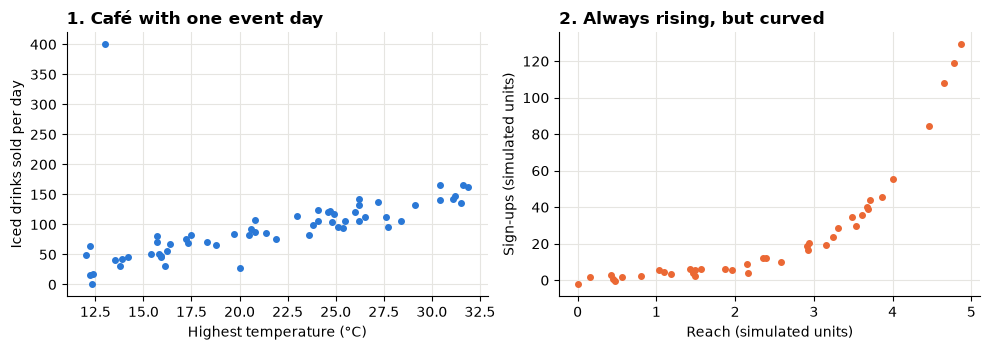

,Pearson r,Spearman
"café, 60 normal days",0.91,0.91
café plus one event day,0.50,0.83
"curved, always rising",0.83,0.97


In [8]:
with_event = pd.concat([cafe, pd.DataFrame({"temp_c": [13.0], "iced_drinks": [400.0]})], ignore_index=True)

rng = np.random.default_rng(seed=3)
reach = np.sort(rng.uniform(0, 5, 40))
signups = np.exp(reach) + rng.normal(0, 2, 40)


def pearson(a, b):
    return pd.Series(a).corr(pd.Series(b))


def spearman(a, b):
    return pd.Series(a).rank().corr(pd.Series(b).rank())


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))
ax1.scatter(with_event["temp_c"], with_event["iced_drinks"], s=16)
ax1.set_title("1. Café with one event day")
ax1.set_xlabel("Highest temperature (°C)")
ax1.set_ylabel("Iced drinks sold per day")
ax2.scatter(reach, signups, s=16, color="#eb6834")
ax2.set_title("2. Always rising, but curved")
ax2.set_xlabel("Reach (simulated units)")
ax2.set_ylabel("Sign-ups (simulated units)")
fig.tight_layout()
plt.show()

pd.DataFrame({
    "Pearson r": [pearson(cafe["temp_c"], cafe["iced_drinks"]),
                  pearson(with_event["temp_c"], with_event["iced_drinks"]),
                  pearson(reach, signups)],
    "Spearman": [spearman(cafe["temp_c"], cafe["iced_drinks"]),
                 spearman(with_event["temp_c"], with_event["iced_drinks"]),
                 spearman(reach, signups)],
}, index=["café, 60 normal days", "café plus one event day", "curved, always rising"]).round(3)

> **Predict, then reveal**
>
> Before reading the table: which measure will drop more when the single event day is added, Pearson or Spearman?

One extreme day pulls Pearson's *r* down noticeably, because Pearson uses the actual distances from the mean. Spearman only sees that the event day ranks first in drinks and near the bottom in temperature, so it moves much less. For the curved case, Spearman is close to 1: the ranks agree almost perfectly, even though the points do not lie on a straight line.

| Prefer… | When… |
|---|---|
| **Pearson** | The relationship looks straight and there are no extreme points; you plan to fit a straight line |
| **Spearman** | There are outliers or very skewed values (sales, income, order sizes); the relationship rises or falls but is curved; the data are ranks or ratings (1–5 stars) |

> **Check your understanding 2**
>
> Customer satisfaction is recorded on a 1–5 scale. You want to know whether it moves with the number of support tickets a customer raised. Which correlation would you use, and why?

---

## Part 4: Correlation is not causation

A correlation says two measures **move together**. It does not say that one **causes** the other. There are three common reasons for a correlation without the cause you hoped for:

| Explanation | What happens | Example |
|---|---|---|
| **Confounder** | A third factor drives both | Hot weather raises both fan sales and iced-drink sales |
| **Reverse causation** | The arrow points the other way | Shops that sell more get a bigger advertising budget, so "advertising" and "sales" move together |
| **Coincidence** | Two series move together by chance, often because both simply grow over time | A company's headcount and the national number of streaming subscribers both rose from 2015 to 2025 |

The cell below simulates a confounder. Temperature drives the sales of **fans** in a shop next door and the café's **iced drinks**. Fans do not make anyone buy a drink.

In [9]:
rng = np.random.default_rng(seed=5)
days = pd.DataFrame({"temp_c": rng.uniform(10, 35, 300).round(1)})
days["fans_sold"] = (2 + 0.8 * days["temp_c"] + rng.normal(0, 3, 300)).round()
days["iced_drinks"] = (-40 + 6 * days["temp_c"] + rng.normal(0, 18, 300)).round()

print("Correlation, fans vs iced drinks, all days:",
      round(days["fans_sold"].corr(days["iced_drinks"]), 2))

days["temp_band"] = pd.cut(days["temp_c"], bins=[10, 15, 20, 25, 30, 35], include_lowest=True)
within = days.groupby("temp_band", observed=True).apply(
    lambda d: pd.Series({"days": len(d), "r_fans_vs_drinks": d["fans_sold"].corr(d["iced_drinks"])}),
    include_groups=False,
).astype({"days": int})
within.round(2)

Correlation, fans vs iced drinks, all days: 0.82


,days,r_fans_vs_drinks
temp_band,,
"(9.999, 15.0]",59,0.09
"(15.0, 20.0]",67,0.09
"(20.0, 25.0]",64,-0.01
"(25.0, 30.0]",50,0.29
"(30.0, 35.0]",60,0.29


Read the output above. Across all days, fans and drinks are strongly correlated. Within days of **similar temperature**, the correlation is weak or close to zero: once the confounder is held roughly fixed, there is little left. Comparing like with like (same temperature, same channel, same season) is the simplest way to check for a confounder. It does not rule out confounders you did not think of.

> **What can prove cause?**
>
> A well-designed **experiment**: change one thing for a randomly chosen group and compare with a group that did not get the change. You do this in the next session (A/B tests). Without an experiment, say *"is associated with"*, not *"causes"* or *"drives"*.

> **Check your understanding 3**
>
> "Customers who use our app spend twice as much as those who do not, so we should push everyone to install the app." Name one confounder and one possible reverse-causation story.

---

## Part 5: Simple linear regression

Correlation gives one number for the strength. **Regression** goes further: it draws the **best straight line** through the points, so you can say *how much* y changes, on average, with x.

*predicted y = intercept + slope × x*

"Best" means the line that makes the **squared vertical distances** from the points to the line as small as possible (*least squares*). numpy finds it with `np.polyfit(x, y, 1)`; the `1` means a straight line (degree 1). It returns the slope first, then the intercept.

Slope:     6.07 drinks per °C
Intercept: -42.09 drinks


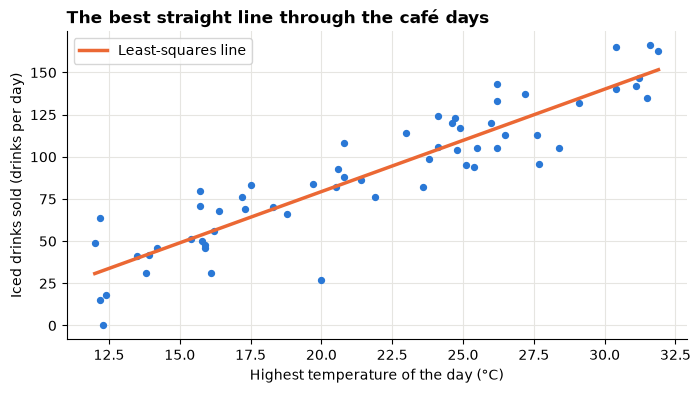

In [10]:
slope, intercept = np.polyfit(cafe["temp_c"], cafe["iced_drinks"], 1)
print(f"Slope:     {slope:.2f} drinks per °C")
print(f"Intercept: {intercept:.2f} drinks")

line_x = np.linspace(cafe["temp_c"].min(), cafe["temp_c"].max(), 100)
ax = cafe.plot.scatter(x="temp_c", y="iced_drinks", s=18)
ax.plot(line_x, intercept + slope * line_x, color="#eb6834", linewidth=2.5, label="Least-squares line")
ax.set_title("The best straight line through the café days")
ax.set_xlabel("Highest temperature of the day (°C)")
ax.set_ylabel("Iced drinks sold (drinks per day)")
ax.legend()
plt.show()

### Say it in business language

| Part | Template | For the café |
|---|---|---|
| **Slope** | "Each extra 1 [unit of x] is **associated with** about [slope] more/fewer [units of y], on average." | Each extra 1 °C is associated with about the slope's number of extra iced drinks a day, on average |
| **Intercept** | "The predicted y when x is 0." | Predicted drinks on a 0 °C day |

Look at the intercept in the output above. A negative number of drinks is impossible, and the café never had a day near 0 °C. The intercept is just where the line crosses the axis; it **only means something if x = 0 is inside the range of the data**. Report the slope; mention the intercept only when it makes sense.

### R²: how much of the variation the line explains

Each day's **residual** is the actual value minus the line's prediction: how far the dot sits above (positive) or below (negative) the line.

- *SS_tot* = sum of squared distances from the **mean**: the total variation in drinks.
- *SS_res* = sum of squared **residuals**: the variation the line leaves unexplained.

*R² = 1 − SS_res ÷ SS_tot*

R² is between 0 and 1. An R² of 0.7 means the line explains about 70% of the day-to-day variation in drinks; the other 30% is everything else.

In [11]:
cafe["predicted"] = intercept + slope * cafe["temp_c"]
cafe["residual"] = cafe["iced_drinks"] - cafe["predicted"]

ss_res = (cafe["residual"] ** 2).sum()
ss_tot = ((cafe["iced_drinks"] - cafe["iced_drinks"].mean()) ** 2).sum()
r_squared = 1 - ss_res / ss_tot

print("SS_res:", round(ss_res), "| SS_tot:", round(ss_tot))
print("R²:", round(r_squared, 3))
print("Pearson r squared:", round(cafe["temp_c"].corr(cafe["iced_drinks"]) ** 2, 3))
print("Average residual:", round(cafe["residual"].mean(), 6))

SS_res: 15544 | SS_tot: 93630
R²: 0.834
Pearson r squared: 0.834
Average residual: 0.0


Two things to notice in the output. For a straight line with one x, **R² equals r²**. And the residuals average to (almost exactly) zero: the line sits in the middle of the cloud.

> **R² is not "how right the model is"**
>
> A high R² does not prove cause, and does not mean the line is the right shape. A low R² can still go with a slope that matters. Always look at the residuals.

### Residual plots

A **residual plot** puts x along the bottom and the residual up the side. If a straight line is the right shape, the residuals form a **shapeless band around zero**. A pattern (a curve, a funnel, a cluster) means the line is missing something.

The second panel below uses a different café that **sells out**: above about 25 °C it cannot make drinks fast enough, so sales level off. We still force a straight line through it.

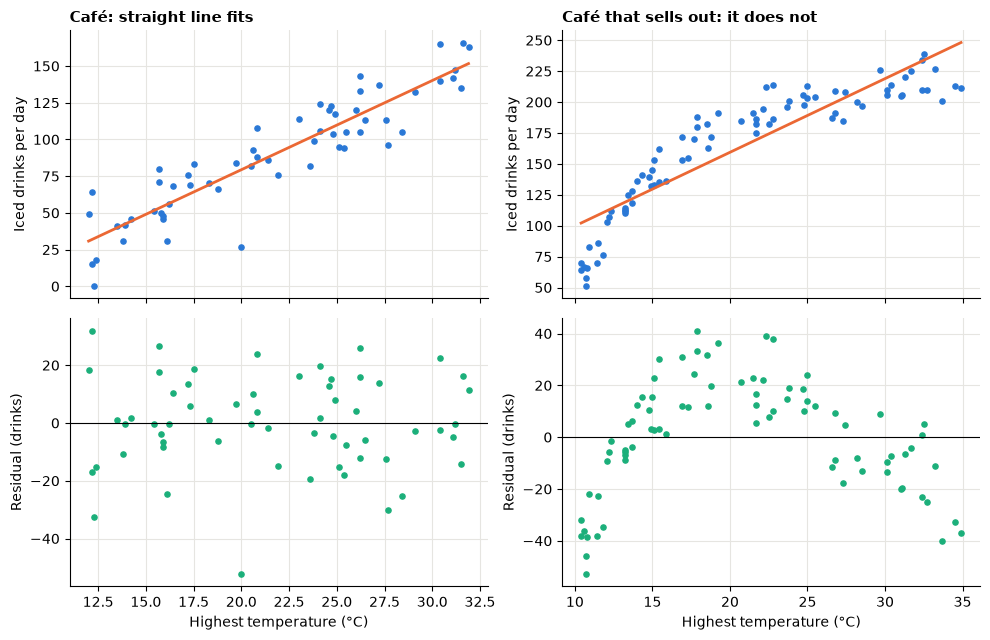

R², café that sells out: 0.806


In [12]:
rng = np.random.default_rng(seed=11)
busy = pd.DataFrame({"temp_c": rng.uniform(10, 35, 80).round(1)})
busy["iced_drinks"] = (220 * (1 - np.exp(-(busy["temp_c"] - 8) / 7)) + rng.normal(0, 10, 80)).round()
b_slope, b_intercept = np.polyfit(busy["temp_c"], busy["iced_drinks"], 1)
busy["residual"] = busy["iced_drinks"] - (b_intercept + b_slope * busy["temp_c"])

fig, axes = plt.subplots(2, 2, figsize=(10, 6.5), sharex="col")
for col, (data, s, i, name) in enumerate([(cafe, slope, intercept, "Café: straight line fits"),
                                          (busy, b_slope, b_intercept, "Café that sells out: it does not")]):
    xs = np.linspace(data["temp_c"].min(), data["temp_c"].max(), 100)
    axes[0, col].scatter(data["temp_c"], data["iced_drinks"], s=14)
    axes[0, col].plot(xs, i + s * xs, color="#eb6834", linewidth=2)
    axes[0, col].set_title(name, fontsize=11)
    axes[0, col].set_ylabel("Iced drinks per day")
    axes[1, col].scatter(data["temp_c"], data["residual"], s=14, color="#1baf7a")
    axes[1, col].axhline(0, color="black", linewidth=0.8)
    axes[1, col].set_xlabel("Highest temperature (°C)")
    axes[1, col].set_ylabel("Residual (drinks)")
fig.tight_layout()
plt.show()
print("R², café that sells out:", round(busy["iced_drinks"].corr(busy["temp_c"]) ** 2, 3))

> **Predict, then reveal**
>
> Look at the bottom-right panel. Where is the line too low, and where is it too high? What does that mean for a prediction on a very hot day?

The residuals form an **arch**: negative at both ends, positive in the middle. The line overpredicts on the hottest days, exactly where the café sells out, even though the R² printed above looks high. The top chart hid this; the residual plot makes it obvious.

> **Check your understanding 4**
>
> A regression of weekly sales on the number of staff on shift has R² = 0.65 and slope 120. Write the slope as one sentence for a manager, and say what the 0.65 means.

---

## Part 6: Outliers and leverage

Least squares uses **squared** distances, so points far from the line count a lot. Where the point sits along the x-axis matters too:

- An **outlier** in the **middle** of the x-range mainly shifts the line up or down.
- A point **far out** along the x-axis has **high leverage**: like a long lever, it can tilt the whole line.

We add one unusual day to the original café data in two different places.

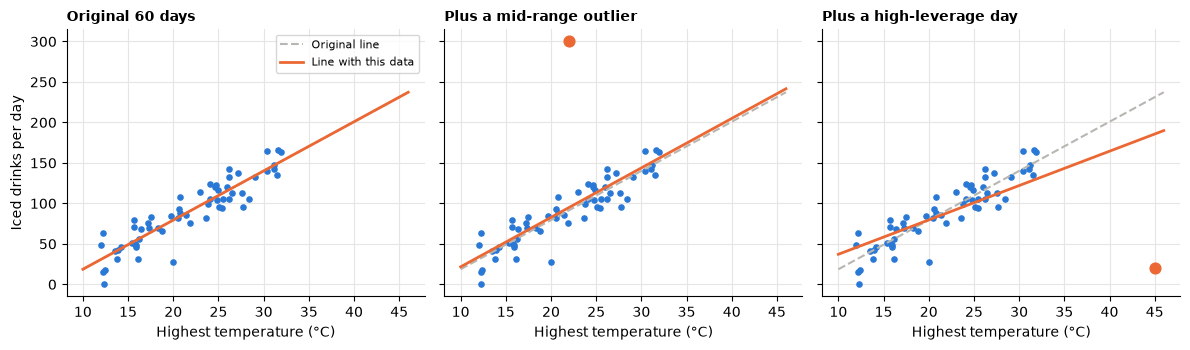

,slope,intercept,R²
original 60 days,6.07,-42.09,0.83
"plus a mid-range outlier (22 °C, 300 drinks)",6.11,-39.47,0.58
"plus a high-leverage day (45 °C, 20 drinks)",4.24,-5.29,0.49


In [13]:
base = cafe[["temp_c", "iced_drinks"]]
scenarios = {
    "original 60 days": base,
    "plus a mid-range outlier (22 °C, 300 drinks)": pd.concat(
        [base, pd.DataFrame({"temp_c": [22.0], "iced_drinks": [300.0]})], ignore_index=True),
    "plus a high-leverage day (45 °C, 20 drinks)": pd.concat(
        [base, pd.DataFrame({"temp_c": [45.0], "iced_drinks": [20.0]})], ignore_index=True),
}

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
rows = {}
for ax, (name, data) in zip(axes, scenarios.items()):
    s, i = np.polyfit(data["temp_c"], data["iced_drinks"], 1)
    xs = np.linspace(10, 46, 100)
    ax.scatter(data["temp_c"], data["iced_drinks"], s=14)
    ax.scatter(data["temp_c"].iloc[60:], data["iced_drinks"].iloc[60:], s=60, color="#eb6834", zorder=3)
    ax.plot(xs, intercept + slope * xs, color="#b8b6b0", linestyle="--", label="Original line")
    ax.plot(xs, i + s * xs, color="#eb6834", linewidth=2, label="Line with this data")
    ax.set_title(name.split(" (")[0].capitalize(), fontsize=10)
    ax.set_xlabel("Highest temperature (°C)")
    rows[name] = {"slope": s, "intercept": i, "R²": data["temp_c"].corr(data["iced_drinks"]) ** 2}
axes[0].set_ylabel("Iced drinks per day")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()
pd.DataFrame(rows).T.round(2)

Read the table above. The mid-range outlier barely changes the slope, although it lowers R² because it adds a lot of unexplained variation. The single day at 45 °C (perhaps the café closed early in a heatwave) flattens the slope a lot and lowers R², although it is one day out of 61.

> **What to do with unusual points**
>
> 1. **Find** them: look at the scatter and residual plots, and at the largest residuals.
> 2. **Check** them: is it a data error, or a real but special day (closure, event, stock-out)?
> 3. **Fit with and without** them and report both if the answer changes. Never delete a point silently because it is inconvenient.

---

## Part 7: The danger of extrapolation

A line is only supported by the data where the data are. Predicting **inside** the observed x-range is **interpolation**; predicting **outside** it is **extrapolation**, and the data cannot tell you whether the line still holds there.

We fit a line to the sell-out café using only the days **up to 22 °C**, then ask it about a 33 °C day.

Temperatures used for the fit: 10.4 to 21.7 °C
18 °C: line predicts 165 drinks
33 °C: line predicts 337 drinks  <- EXTRAPOLATION: outside the data used
Actual average on days of 31–35 °C: 217 drinks


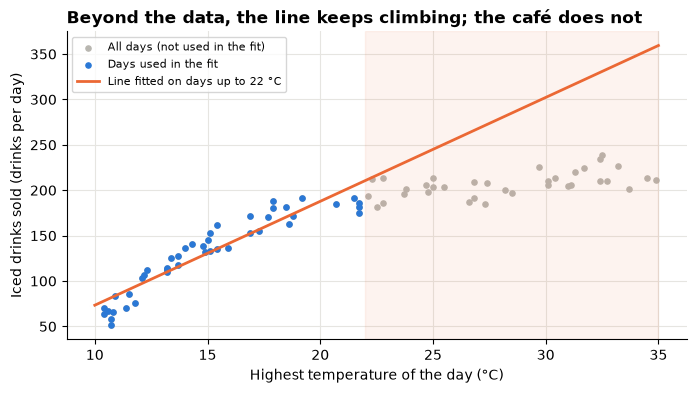

In [14]:
cool = busy[busy["temp_c"] <= 22]
c_slope, c_intercept = np.polyfit(cool["temp_c"], cool["iced_drinks"], 1)

print("Temperatures used for the fit:", cool["temp_c"].min(), "to", cool["temp_c"].max(), "°C")
for t in [18, 33]:
    inside = cool["temp_c"].min() <= t <= cool["temp_c"].max()
    print(f"{t} °C: line predicts {c_intercept + c_slope * t:.0f} drinks"
          f"{'' if inside else '  <- EXTRAPOLATION: outside the data used'}")
print("Actual average on days of 31–35 °C:",
      round(busy.loc[busy["temp_c"] >= 31, "iced_drinks"].mean()), "drinks")

xs = np.linspace(10, 35, 100)
ax = busy.plot.scatter(x="temp_c", y="iced_drinks", s=14, color="#b8b6b0", label="All days (not used in the fit)")
cool.plot.scatter(x="temp_c", y="iced_drinks", s=14, ax=ax, label="Days used in the fit")
ax.plot(xs, c_intercept + c_slope * xs, color="#eb6834", linewidth=2, label="Line fitted on days up to 22 °C")
ax.axvspan(22, 35, color="#eb6834", alpha=0.08)
ax.set_title("Beyond the data, the line keeps climbing; the café does not")
ax.set_xlabel("Highest temperature of the day (°C)")
ax.set_ylabel("Iced drinks sold (drinks per day)")
ax.legend(fontsize=8)
plt.show()

Read the output above. Inside the range, the prediction is reasonable. At 33 °C the line predicts far more drinks than the café actually sold on such days, because the relationship changed shape where we had no data.

> **Rule**
>
> Always state the range of x behind a regression, and flag any prediction outside it. "Double the budget" is usually extrapolation: you have never observed that budget.

> **Check your understanding 5**
>
> A line fitted to shops of 100–400 square metres predicts sales for a planned 1,500 square-metre store. What would you tell the planning team?

---

## Part 8: Worked case — advertising spend and revenue

> **About the data**
>
> `marketing_daily.csv` is **synthetic**: generated for this course, describing no real company or platform. One row per **day of 2025 × campaign**: seven paid campaigns in five channels (Search, Social, Display, Video, Email). Amounts are in neutral **currency units**. `attributed_revenue` is the revenue of purchases credited to that campaign on that day.

The marketing lead asks: *"How much revenue does one more unit of advertising spend bring?"*

### Step 1: Load and check the grain

In [15]:
mkt = load_marketing("marketing_daily.csv")
print("Rows:", len(mkt), "| days:", mkt["date"].nunique(), "| campaigns:", mkt["campaign_id"].nunique())
print("Rows with zero spend (paused days, free email sends):", (mkt["spend"] == 0).sum())
mkt.groupby(["channel", "campaign_id"]).agg(
    days=("date", "count"), total_spend=("spend", "sum"), total_revenue=("attributed_revenue", "sum")
).round(0)

Rows: 2555 | days: 365 | campaigns: 7
Rows with zero spend (paused days, free email sends): 39


days  total_spend  total_revenue
channel campaign_id                                  
Display DISP-01       365   207,556.00     132,219.00
Email   EML-01        365    15,426.00     451,164.00
Search  SRCH-01       365   362,654.00   2,897,732.00
        SRCH-02       365   256,844.00   1,589,253.00
Social  SOC-01        365   433,454.00     595,050.00
        SOC-02        365    24,001.00     315,601.00
Video   VID-01        365   169,990.00      68,083.00

Days with **zero spend** cannot tell us what spend buys (and some have revenue from free email sends), so we leave them out of the regressions and say so.

### Step 2: Pool every campaign-day, or look within each channel?

The quickest analysis throws all campaign-days into one scatter and fits one line. The cell below does that, and then fits a separate line **within each channel**.

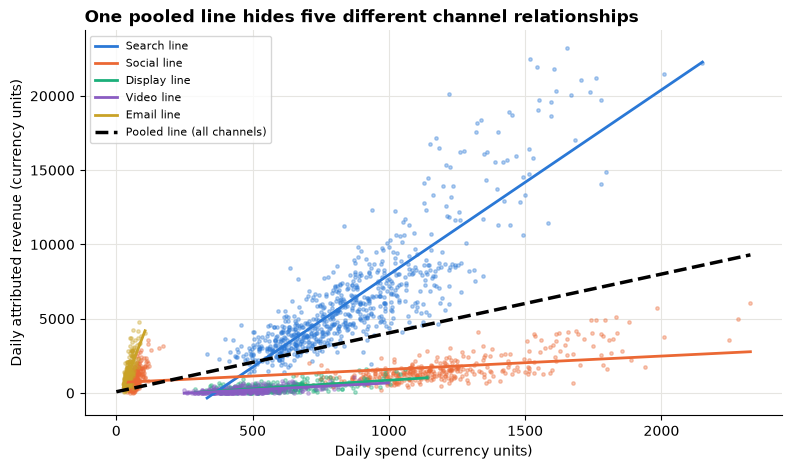

,campaign-days,r,slope
Search,719,0.86,12.44
Social,719,0.61,0.90
Display,362,0.58,1.16
Video,363,0.58,0.92
Email,353,0.72,47.86
All channels pooled,2516,0.53,3.96


In [16]:
paid = mkt[mkt["spend"] > 0]
channels = ["Search", "Social", "Display", "Video", "Email"]
colours = ["#2a78d6", "#eb6834", "#1baf7a", "#8a5cc2", "#c9a227"]

fig, ax = plt.subplots(figsize=(9, 5))
summary = {}
for ch, colour in zip(channels, colours):
    d = paid[paid["channel"] == ch]
    s, i = np.polyfit(d["spend"], d["attributed_revenue"], 1)
    xs = np.linspace(d["spend"].min(), d["spend"].max(), 50)
    ax.scatter(d["spend"], d["attributed_revenue"], s=6, alpha=0.35, color=colour)
    ax.plot(xs, i + s * xs, color=colour, linewidth=2, label=f"{ch} line")
    summary[ch] = {"campaign-days": len(d), "r": d["spend"].corr(d["attributed_revenue"]), "slope": s}

pooled_s, pooled_i = np.polyfit(paid["spend"], paid["attributed_revenue"], 1)
xs = np.linspace(0, paid["spend"].max(), 50)
ax.plot(xs, pooled_i + pooled_s * xs, color="black", linewidth=2.5, linestyle="--", label="Pooled line (all channels)")
summary["All channels pooled"] = {"campaign-days": len(paid),
                                  "r": paid["spend"].corr(paid["attributed_revenue"]), "slope": pooled_s}
ax.set_title("One pooled line hides five different channel relationships")
ax.set_xlabel("Daily spend (currency units)")
ax.set_ylabel("Daily attributed revenue (currency units)")
ax.legend(fontsize=8)
plt.show()
pd.DataFrame(summary).T.astype({"campaign-days": int}).round(2)

> **Predict, then reveal**
>
> Before reading the table: is the pooled slope close to any one channel's slope?

The pooled slope does not describe any channel. Channels differ in **both** how much they spend per day and how much revenue each unit brings: Social, Display and Video spend hundreds or thousands of units a day but bring back little per unit; Search spends similar amounts and brings back much more; Email spends very little. The pooled line runs between these groups. **Channel is a confounder**: it drives both spend and revenue per unit. Mixing them gives a line that answers no real question. Compare like with like: one line per channel, or better, per campaign.

### Step 3: A hidden confounder in time

Now add up all campaigns per **day** and fit spend against revenue for the whole company, first for all of 2025 and then for January–September only.

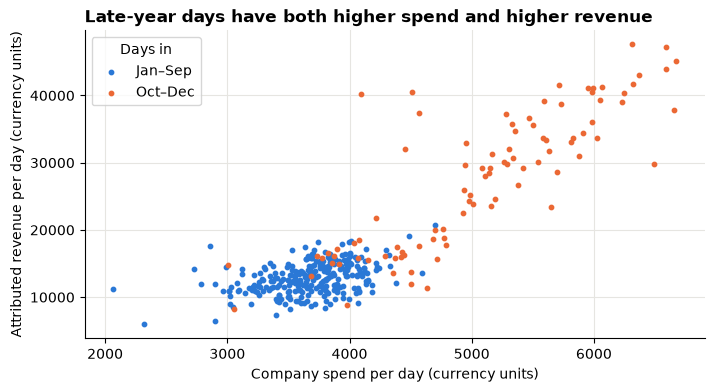

,days,slope,R²
All of 2025,365,9.23,0.77
Jan–Sep only,273,2.64,0.16


In [17]:
daily = mkt.groupby("date")[["spend", "attributed_revenue"]].sum()
daily["season"] = np.where(daily.index.month >= 10, "Oct–Dec", "Jan–Sep")

fits = {}
for name, d in [("All of 2025", daily), ("Jan–Sep only", daily[daily["season"] == "Jan–Sep"])]:
    s, i = np.polyfit(d["spend"], d["attributed_revenue"], 1)
    fits[name] = {"days": len(d), "slope": s, "R²": d["spend"].corr(d["attributed_revenue"]) ** 2}

fig, ax = plt.subplots()
for season, colour in [("Jan–Sep", "#2a78d6"), ("Oct–Dec", "#eb6834")]:
    d = daily[daily["season"] == season]
    ax.scatter(d["spend"], d["attributed_revenue"], s=10, color=colour, label=season)
ax.set_title("Late-year days have both higher spend and higher revenue")
ax.set_xlabel("Company spend per day (currency units)")
ax.set_ylabel("Attributed revenue per day (currency units)")
ax.legend(title="Days in")
plt.show()
pd.DataFrame(fits).T.astype({"days": int}).round(2)

Read the table above. The full-year slope is several times the January–September slope. The chart suggests why: the late-year days sit together at the top right. A likely story is that budgets were raised for the holiday season, when customers buy more anyway. If season pushes spend and revenue up together, the full-year line credits advertising with revenue that the season brought. Here **season is a confounder**.

### Step 4: Slope, ROAS and what extra spend would really bring

| Measure | How it is calculated | What it answers |
|---|---|---|
| **ROAS** (return on ad spend) | total attributed revenue ÷ total spend (a ratio of sums) | On average, how much revenue was credited per unit of spend so far |
| **Regression slope** | best line through daily spend vs revenue | How revenue **moved with** spend across these days |
| **Incremental effect** | revenue *with* the extra spend minus revenue *without* it | What one more unit of spend would **cause** |

Neither ROAS nor the slope is the incremental effect:

1. Days with higher spend may differ in other ways (season, channel, promotions): **confounding**.
2. The attribution credits purchases to a campaign; some of those customers would have bought anyway.
3. Spend changes within the observed range tell you little about spend far outside it: **extrapolation**. Returns often **diminish**: the second thousand units buys fewer new customers than the first.

The way to measure the incremental effect is an **experiment**, for example raising spend in randomly chosen weeks or regions and comparing with the rest. That is the next session.

> **A careful sentence for the marketing lead**
>
> "For [campaign], January–September 2025, each extra unit of daily spend was **associated with** about [slope] more units of attributed revenue (R² = [value], daily spend between [min] and [max]). This is an association: it does not prove that more spend would cause more revenue, and it does not hold outside the spend range we observed."

---

## Summary

| Question | Tool | Trap to avoid |
|---|---|---|
| Do two measures move together? | Scatter plot | Reading only the number |
| How strong is the straight-line link? | Pearson *r* | Missing a curve or an outlier |
| Does y rise or fall with x, whatever the shape? | Spearman (Pearson on ranks) | Using Pearson on skewed or ranked data |
| Does x cause y? | An experiment | Confounders, reverse causation, coincidence |
| How much does y change per unit of x? | Regression slope (`np.polyfit`) | Interpreting the intercept outside the data |
| How much variation does the line explain? | R² = 1 − SS_res ÷ SS_tot | Treating high R² as proof or as the right shape |
| Is a straight line the right shape? | Residual plot | Ignoring patterns in residuals |
| Can one point change the answer? | Fit with and without it | High-leverage points; silent deletion |
| Can I predict for a new x? | Only inside the observed range | Extrapolation, "double the budget" |

---

## Quiz

Answer these at the start of the next lecture. Write short answers.

1. A scatter plot shows dots rising from bottom left to top right and lying close to a line. Describe the relationship in words, and give a plausible range for *r*.
2. Why does correlation not change when you convert a measure from euros to cents, while covariance does?
3. Give one situation where you would prefer Spearman to Pearson correlation, and say why.
4. Ice-cream sales and drowning incidents are positively correlated. What is the most likely explanation?
5. A regression of monthly sales (currency units) on advertising spend (currency units) has slope 3.2. Write one sentence for a manager, using "associated with".
6. What is a residual, and what should a residual plot look like if a straight line is the right shape?
7. Why can one shop that is much bigger than the others change a regression line so much?
8. Your data cover daily spend between 500 and 2,000. A colleague wants a prediction for 6,000. What do you say?

---

## Lab briefing

In the **Lab** you:

1. Measure how discount relates to profit ratio in the retail orders, line by line and order by order, and explain why the two pictures differ.
2. Fit a line to one advertising campaign's daily spend and revenue, interpret the slope, read the residuals and flag extrapolation.
3. Compare channels and see what pooling hides.
4. Meet Anscombe's quartet: four datasets with the same line and very different stories.
5. Debug a colleague's "double the budget" claim.

Open the [Session 8 lab](08_correlation_and_regression_lab.md).